In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pandas as pd
df = pd.read_excel("/content/drive/MyDrive/SEMESTER 7/2. Coffee_Sales.xlsx")
df.head()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [4]:
# Mengubah tanggal ke format datetime
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"],
    errors="coerce"
)

# Mengubah kuantitas menjadi numerik
df["transaction_qty"] = pd.to_numeric(
    df["transaction_qty"],
    errors="coerce"
)

# Menghapus baris yang tanggal atau kuantitasnya tidak valid
df = df.dropna(
    subset=["transaction_date", "transaction_qty", "store_location"]
)

# Memastikan kuantitas tidak negatif
df = df[df["transaction_qty"] >= 0]

# Memilih satu lokasi
df_lokasi = df[
    df["store_location"] == "Hell's Kitchen"
].copy()

print("Jumlah baris setelah filter:", len(df_lokasi))
print("Tanggal awal:", df_lokasi["transaction_date"].min())
print("Tanggal akhir:", df_lokasi["transaction_date"].max())

display(df_lokasi.head())

Jumlah baris setelah filter: 50735
Tanggal awal: 2023-01-01 00:00:00
Tanggal akhir: 2023-06-30 00:00:00


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
17,18,2023-01-01,08:00:18,1,8,Hell's Kitchen,42,2.50,Tea,Brewed herbal tea,Lemon Grass Rg
18,19,2023-01-01,08:00:39,2,8,Hell's Kitchen,59,4.50,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
19,20,2023-01-01,08:11:45,1,8,Hell's Kitchen,61,4.75,Drinking Chocolate,Hot chocolate,Sustainably Grown Organic Lg
20,21,2023-01-01,08:17:27,2,8,Hell's Kitchen,33,3.50,Coffee,Gourmet brewed coffee,Ethiopia Lg
23,24,2023-01-01,08:29:38,1,8,Hell's Kitchen,56,2.55,Tea,Brewed Chai tea,Spicy Eye Opener Chai Rg


In [5]:
# Menjumlahkan kuantitas penjualan setiap hari
data_harian = (
    df_lokasi
    .groupby("transaction_date")["transaction_qty"]
    .sum()
    .reset_index()
)

# Menyesuaikan nama kolom untuk Prophet
data_harian = data_harian.rename(
    columns={
        "transaction_date": "ds",
        "transaction_qty": "y"
    }
)

# Membuat rentang tanggal harian yang lengkap
rentang_tanggal = pd.date_range(
    start=data_harian["ds"].min(),
    end=data_harian["ds"].max(),
    freq="D"
)

data_harian = (
    data_harian
    .set_index("ds")
    .reindex(rentang_tanggal, fill_value=0)
    .rename_axis("ds")
    .reset_index()
)

print("Jumlah data harian:", len(data_harian))
print("\nData harian:")
display(data_harian.head(10))

Jumlah data harian: 181

Data harian:


,ds,y
0,2023-01-01,270
1,2023-01-02,272
2,2023-01-03,295
3,2023-01-04,256
4,2023-01-05,235
5,2023-01-06,256
6,2023-01-07,323
7,2023-01-08,277
8,2023-01-09,272
9,2023-01-10,273


# EKSPLORASI DATA

Jumlah observasi: 181
Rentang tanggal: 2023-01-01 00:00:00 sampai 2023-06-30 00:00:00
Tanggal duplikat: 0
Nilai kosong:
 ds    0
y     0
dtype: int64
Jumlah hari tanpa penjualan: 0

Statistik deskriptif:
count    181.000000
mean     396.337017
std      129.535462
min      195.000000
25%      290.000000
50%      363.000000
75%      483.000000
max      769.000000
Name: y, dtype: float64


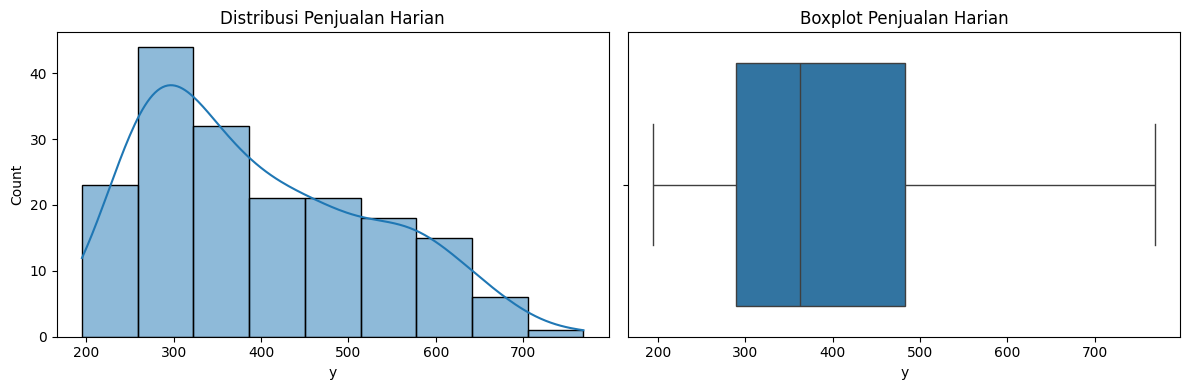

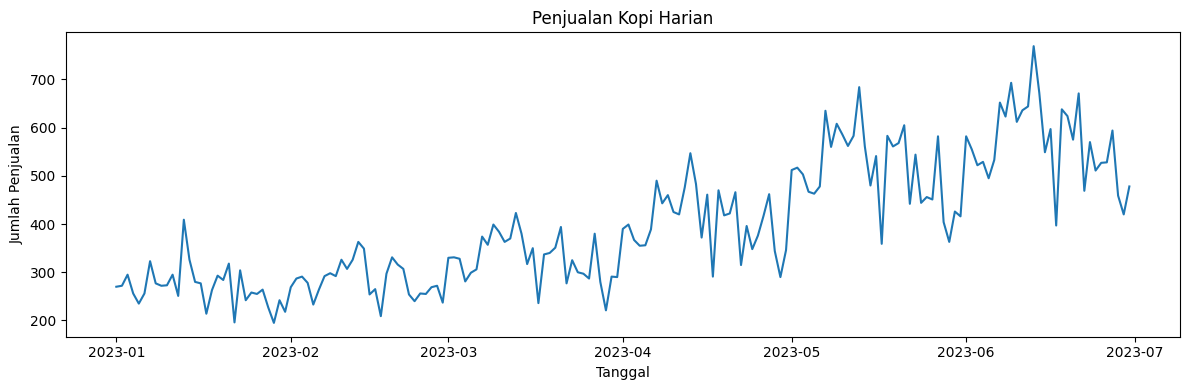

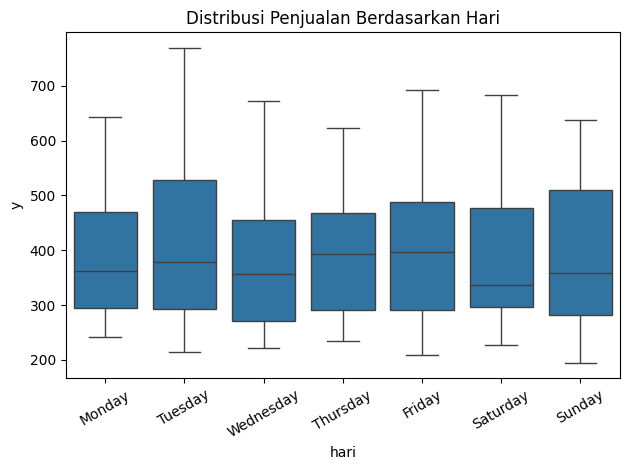

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

# Ringkasan data
print("Jumlah observasi:", len(data_harian))
print("Rentang tanggal:", data_harian["ds"].min(), "sampai", data_harian["ds"].max())
print("Tanggal duplikat:", data_harian["ds"].duplicated().sum())
print("Nilai kosong:\n", data_harian[["ds", "y"]].isna().sum())
print("Jumlah hari tanpa penjualan:", (data_harian["y"] == 0).sum())
print("\nStatistik deskriptif:")
print(data_harian["y"].describe())

# Distribusi penjualan
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data_harian["y"], kde=True, ax=ax[0])
ax[0].set_title("Distribusi Penjualan Harian")
sns.boxplot(x=data_harian["y"], ax=ax[1])
ax[1].set_title("Boxplot Penjualan Harian")
plt.tight_layout()
plt.show()

# Tren penjualan
plt.figure(figsize=(12, 4))
plt.plot(data_harian["ds"], data_harian["y"])
plt.title("Penjualan Kopi Harian")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Penjualan")
plt.tight_layout()
plt.show()

# Pola berdasarkan hari dalam seminggu
sementara = data_harian.copy()
sementara["hari"] = sementara["ds"].dt.day_name()
urutan_hari = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]
sns.boxplot(data=sementara, x="hari", y="y", order=urutan_hari)
plt.xticks(rotation=30)
plt.title("Distribusi Penjualan Berdasarkan Hari")
plt.tight_layout()
plt.show()

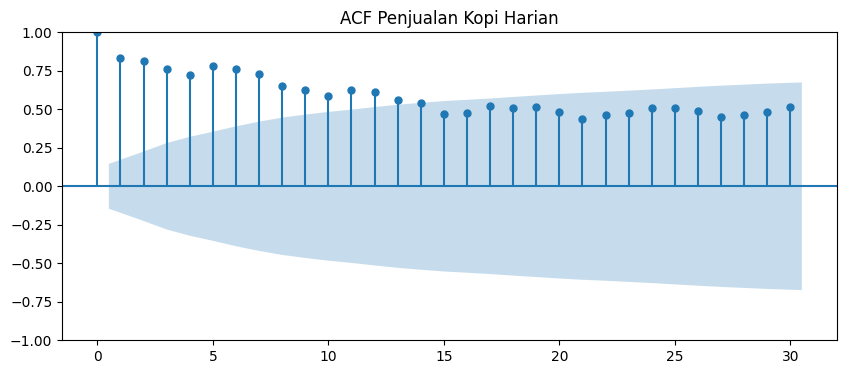

        lb_stat      lb_pvalue
7    782.228200  1.268425e-164
14  1274.174217  1.943335e-263
21  1611.710839   0.000000e+00


In [7]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

y = data_harian.sort_values("ds")["y"]

fig, ax = plt.subplots(figsize=(10, 4))
plot_acf(y, lags=30, ax=ax)
plt.title("ACF Penjualan Kopi Harian")
plt.show()

hasil = acorr_ljungbox(y, lags=[7, 14, 21], return_df=True)
print(hasil)

In [8]:
# ==============================
# 1. SPLIT TRAIN-TEST (80:20)
# ==============================
n = len(data_harian)
batas_train = int(n * 0.8)

train_80 = data_harian.iloc[:batas_train].copy()
test_20 = data_harian.iloc[batas_train:].copy()

print("SPLIT TRAIN-TEST (80:20)")
print(f"Train: {len(train_80)} data | {train_80['ds'].min()} - {train_80['ds'].max()}")
print(f"Test : {len(test_20)} data | {test_20['ds'].min()} - {test_20['ds'].max()}")


# ==============================
# 2. SPLIT TRAIN-VALIDATION-TEST (80:10:10)
# ==============================
batas_train = int(n * 0.8)
batas_val = int(n * 0.9)

train_80_10_10 = data_harian.iloc[:batas_train].copy()
val_10 = data_harian.iloc[batas_train:batas_val].copy()
test_10 = data_harian.iloc[batas_val:].copy()

print("\nSPLIT TRAIN-VALIDATION-TEST (80:10:10)")
print(f"Train: {len(train_80_10_10)} data | {train_80_10_10['ds'].min()} - {train_80_10_10['ds'].max()}")
print(f"Val  : {len(val_10)} data | {val_10['ds'].min()} - {val_10['ds'].max()}")
print(f"Test : {len(test_10)} data | {test_10['ds'].min()} - {test_10['ds'].max()}")

SPLIT TRAIN-TEST (80:20)
Train: 144 data | 2023-01-01 00:00:00 - 2023-05-24 00:00:00
Test : 37 data | 2023-05-25 00:00:00 - 2023-06-30 00:00:00

SPLIT TRAIN-VALIDATION-TEST (80:10:10)
Train: 144 data | 2023-01-01 00:00:00 - 2023-05-24 00:00:00
Val  : 18 data | 2023-05-25 00:00:00 - 2023-06-11 00:00:00
Test : 19 data | 2023-06-12 00:00:00 - 2023-06-30 00:00:00


In [9]:
import numpy as np
import pandas as pd

# Moving Block Bootstrap (MBB)
def moving_block_bootstrap(data, block_size=7, random_state=42):
    rng = np.random.default_rng(random_state)
    values = data["y"].to_numpy()
    n = len(values)

    # Seluruh blok berurutan dengan panjang 7 hari
    blocks = np.array([
        values[i:i + block_size]
        for i in range(n - block_size + 1)
    ])

    # Ambil blok acak sampai jumlah observasi tercapai
    n_blocks = int(np.ceil(n / block_size))
    sampled_idx = rng.integers(0, len(blocks), size=n_blocks)
    synthetic = np.concatenate(blocks[sampled_idx])[:n]

    return pd.DataFrame({
        "ds": data["ds"].to_numpy(),
        "y": synthetic
    })

# Buat data sintetis dari training saja
train_mbb = moving_block_bootstrap(train_80, block_size=7)

# Gabungkan data training asli dan sintetis
train_augmented = pd.concat(
    [train_80, train_mbb],
    ignore_index=True
).sort_values("ds").reset_index(drop=True)

print("Jumlah data training asli:", len(train_80))
print("Jumlah data sintetis:", len(train_mbb))
print("Jumlah data training setelah augmentasi:", len(train_augmented))
print("Jumlah data testing:", len(test_20))


Jumlah data training asli: 144
Jumlah data sintetis: 144
Jumlah data training setelah augmentasi: 288
Jumlah data testing: 37


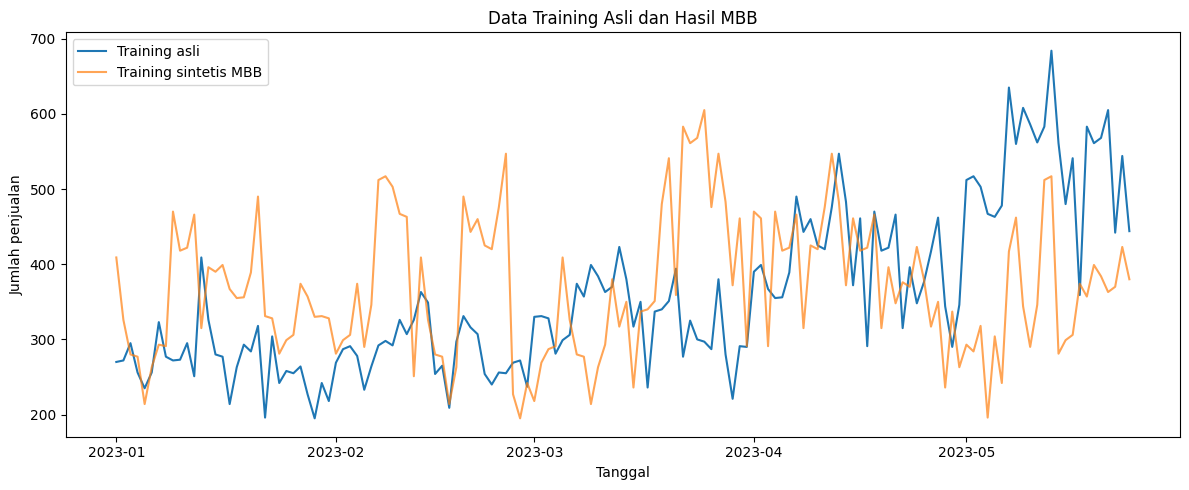

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(train_80["ds"], train_80["y"], label="Training asli")
plt.plot(train_mbb["ds"], train_mbb["y"],
         label="Training sintetis MBB", alpha=0.7)
plt.xlabel("Tanggal")
plt.ylabel("Jumlah penjualan")
plt.title("Data Training Asli dan Hasil MBB")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
from statsmodels.tsa.stattools import adfuller, kpss
import pandas as pd

dataset_list = [('Training Asli', train_80), ('Training MBB', train_mbb)]

df_res = pd.DataFrame([{
    'Dataset': nama,
    'ADF p-value': round(a := adfuller(d['y'].dropna())[1], 4),
    'Status ADF': 'Stasioner' if a < 0.05 else 'Tidak stasioner',
    'KPSS p-value': round(k := kpss(d['y'].dropna(), regression='c', nlags='auto')[1], 4),
    'Status KPSS': 'Stasioner' if k > 0.05 else 'Tidak stasioner'
} for nama, d in dataset_list])

display(df_res)

/tmp/ipykernel_53154/1452974172.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  'ADF p-value': round(a := adfuller(d['y'].dropna())[1], 4),
/tmp/ipykernel_53154/1452974172.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  'KPSS p-value': round(k := kpss(d['y'].dropna(), regression='c', nlags='auto')[1], 4),
/tmp/ipykernel_53154/1452974172.py:10: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is late

,Dataset,ADF p-value,Status ADF,KPSS p-value,Status KPSS
0,Training Asli,0.6579,Tidak stasioner,0.01,Tidak stasioner
1,Training MBB,0.0002,Stasioner,0.10,Stasioner


In [13]:

from statsmodels.tsa.stattools import adfuller, kpss

train_80_diff = train_80.copy()
train_80_diff['y'] = train_80['y'].diff()
s = train_80_diff['y'].dropna()

a, k = adfuller(s)[1], kpss(s, regression='c', nlags='auto')[1]

display(pd.DataFrame([{
    'Dataset': 'Training Asli (d=1)',
    'ADF p-value': round(a, 4),
    'Status ADF': 'Stasioner' if a < 0.05 else 'Tidak stasioner',
    'KPSS p-value': round(k, 4),
    'Status KPSS': 'Stasioner' if k > 0.05 else 'Tidak stasioner'
}]))

/tmp/ipykernel_53154/3941406711.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  a, k = adfuller(s)[1], kpss(s, regression='c', nlags='auto')[1]
/tmp/ipykernel_53154/3941406711.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  a, k = adfuller(s)[1], kpss(s, regression='c', nlags='auto')[1]
/tmp/ipykernel_53154/3941406711.py:7: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavi

,Dataset,ADF p-value,Status ADF,KPSS p-value,Status KPSS
0,Training Asli (d=1),0.0004,Stasioner,0.1,Stasioner


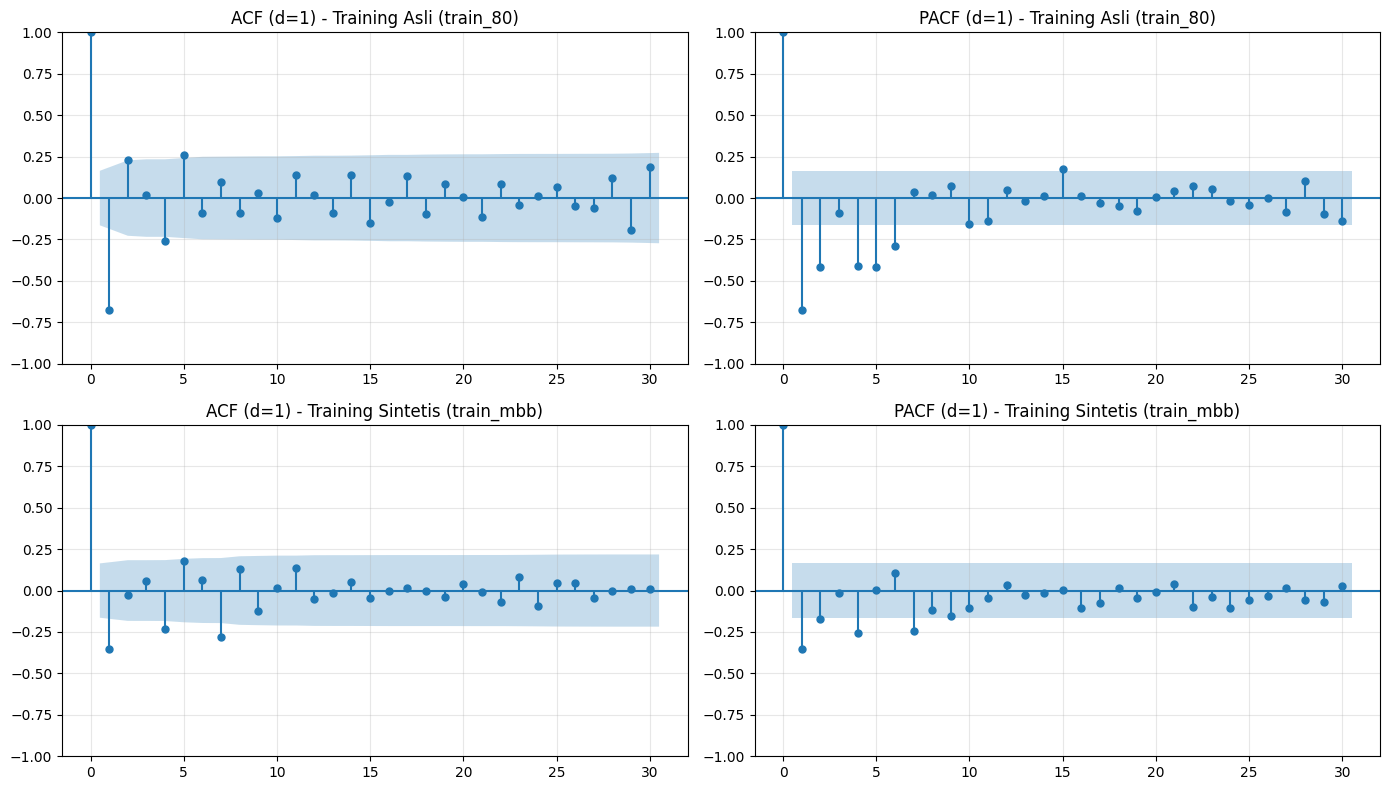

In [14]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

dataset_list = [
    ('Training Asli (train_80)', train_80_diff),
    ('Training Sintetis (train_mbb)', train_mbb)
]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for idx, (nama, data) in enumerate(dataset_list):
    s_diff = data['y'].diff().dropna()

    plot_acf(s_diff, ax=axes[idx, 0], lags=30)
    axes[idx, 0].set_title(f'ACF (d=1) - {nama}')
    axes[idx, 0].grid(True, alpha=0.3)

    plot_pacf(s_diff, ax=axes[idx, 1], lags=30, method='ywm')
    axes[idx, 1].set_title(f'PACF (d=1) - {nama}')
    axes[idx, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:

import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings
warnings.filterwarnings("ignore")

dataset_list = [
    ('Training Asli', train_80['y'].dropna(), 1),
    ('Training MBB', train_mbb['y'].dropna(), 0)
]

model_arima = [(0,1,1), (1,1,1), (2,1,1), (5,1,1), (0,1,5)]
model_sarima = [
    ((0,1,1), (0,1,1,7)),
    ((1,1,1), (1,1,1,7)),
    ((1,1,1), (0,1,1,7))
]

hasil = []

for nama, y, d in dataset_list:
    for p, _, q in model_arima:
        order = (p, d, q)
        try:
            fit = ARIMA(y, order=order).fit()
            hasil.append([nama, f'ARIMA{order}', fit.aic, fit.bic])
        except Exception as e:
            print(f'Gagal ARIMA{order} ({nama}): {e}')

    for order, seasonal in model_sarima:
        order = (order[0], d, order[2])
        seasonal = (seasonal[0], 1 if d == 1 else 0, seasonal[2], seasonal[3])
        try:
            fit = SARIMAX(
                y, order=order, seasonal_order=seasonal,
                enforce_stationarity=False,
                enforce_invertibility=False
            ).fit(disp=False)
            hasil.append([
                nama, f'SARIMA{order}x{seasonal}', fit.aic, fit.bic
            ])
        except Exception as e:
            print(f'Gagal SARIMA{order}x{seasonal} ({nama}): {e}')

df_aic_bic = pd.DataFrame(
    hasil, columns=['Dataset', 'Model', 'AIC', 'BIC']
)
df_aic_bic[['AIC', 'BIC']] = df_aic_bic[['AIC', 'BIC']].round(2)

display(df_aic_bic.sort_values(['Dataset', 'AIC']).reset_index(drop=True))

,Dataset,Model,AIC,BIC
0,Training Asli,"SARIMA(1, 1, 1)x(0, 1, 1, 7)",1417.29,1428.67
1,Training Asli,"SARIMA(0, 1, 1)x(0, 1, 1, 7)",1417.76,1426.29
2,Training Asli,"SARIMA(1, 1, 1)x(1, 1, 1, 7)",1419.04,1433.26
3,Training Asli,"ARIMA(5, 1, 1)",1551.98,1572.72
4,Training Asli,"ARIMA(0, 1, 5)",1552.64,1570.42
5,Training Asli,"ARIMA(0, 1, 1)",1571.24,1577.17
6,Training Asli,"ARIMA(1, 1, 1)",1572.19,1581.08
7,Training Asli,"ARIMA(2, 1, 1)",1572.71,1584.56
8,Training MBB,"SARIMA(1, 0, 1)x(0, 0, 1, 7)",1561.96,1573.58
9,Training MBB,"SARIMA(1, 0, 1)x(1, 0, 1, 7)",1563.70,1578.22


In [17]:

import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings("ignore")

models = [
    ('ARIMA', (0,0,1), None), ('ARIMA', (1,0,1), None),
    ('ARIMA', (2,0,1), None), ('ARIMA', (5,0,1), None),
    ('ARIMA', (0,0,5), None),
    ('SARIMA', (0,0,1), (0,0,1,7)),
    ('SARIMA', (1,0,1), (1,0,1,7)),
    ('SARIMA', (1,0,1), (0,0,1,7))
]

hasil = []
y_test = test_20['y'].dropna()

for nama, train, d in [
    ('Training Asli', train_80['y'].dropna(), 1),
    ('Training MBB', train_mbb['y'].dropna(), 0)
]:
    for jenis, order, seasonal in models:
        order = (order[0], d, order[2])
        try:
            if jenis == 'ARIMA':
                fit = ARIMA(train, order=order).fit()
            else:
                seas = (seasonal[0], 1 if d == 1 else 0,
                        seasonal[2], seasonal[3])
                fit = SARIMAX(train, order=order, seasonal_order=seas,
                              enforce_stationarity=False,
                              enforce_invertibility=False).fit(disp=False)

            pred = fit.forecast(len(y_test))
            mae = mean_absolute_error(y_test, pred)
            rmse = np.sqrt(mean_squared_error(y_test, pred))
            mape = np.mean(np.abs((y_test.to_numpy() - pred.to_numpy())
                                  / y_test.to_numpy())) * 100

            hasil.append([nama, f'{jenis}{order}' +
                          (f'x{seas}' if jenis == 'SARIMA' else ''),
                          mae, rmse, mape])
        except Exception as e:
            print(f'Gagal {nama}, {jenis}{order}: {e}')

df_eval = pd.DataFrame(
    hasil, columns=['Dataset', 'Model', 'MAE', 'RMSE', 'MAPE (%)']
)
display(df_eval.round(3).sort_values(['Dataset', 'RMSE']))

,Dataset,Model,MAE,RMSE,MAPE (%)
5,Training Asli,"SARIMA(0, 1, 1)x(0, 1, 1, 7)",78.133,94.883,14.878
6,Training Asli,"SARIMA(1, 1, 1)x(1, 1, 1, 7)",80.537,96.011,15.678
7,Training Asli,"SARIMA(1, 1, 1)x(0, 1, 1, 7)",80.817,96.219,15.756
3,Training Asli,"ARIMA(5, 1, 1)",84.270,100.835,15.303
2,Training Asli,"ARIMA(2, 1, 1)",83.864,100.895,15.111
4,Training Asli,"ARIMA(0, 1, 5)",87.188,103.856,15.732
1,Training Asli,"ARIMA(1, 1, 1)",86.954,104.181,15.516
0,Training Asli,"ARIMA(0, 1, 1)",88.735,106.223,15.739
9,Training MBB,"ARIMA(1, 0, 1)",175.882,199.545,30.046
10,Training MBB,"ARIMA(2, 0, 1)",175.868,199.551,30.042
